# Module 3 Homework - Seaborn

Using a dataset about Pokemon combat statistic, we will practice data visualization using the seaborn library.
<img src="https://lh3.googleusercontent.com/v-xCiSuC-wfd033abL8V3YdI4dw-wcAs9nebYt_Y-STHMNupkyE0G7kiwzYLfCwWxEYNDNlHYOwuH8imqr9CAO0s7hwU-qQn7cM=e365-pa-nu-w3840">

In this notebook, we will plot the relationships between different observations of the combat statistics of Pokémon. You will need to import a few packages, including `pandas`, `matplotlib.pyplot`, and `seaborn`. The data is stored in a csv file: https://raw.githubusercontent.com/csbfx/advpy122-data/master/Pokemon.csv

Here are the descriptions of this dataset:
- `#` - Pokedex entry number of the Pokemon
- `Name` - name of the Pokemon
- `Type 1` - each Pokemon has a type, this determines weakness/resistance to attacks [referred to as the primary type]
- `Type 2` - some Pokemon are dual type and have 2 [referred to as the secondary type]
- `Total` - sum of all stats that come after this, a general guide to how strong a Pokemon is
- `HP` - hit points, or health, defines how much damage a Pokemon can withstand before fainting
- `Attack` - the base modifier for normal attacks
- `Defense` - the base damage resistance against normal attacks
- `Sp. Atk` - special attack, the base modifier for special attacks
- `Sp. Def` - the base damage resistance against special attacks
- `Speed` - determines which Pokemon attacks first each round
- `Generation` - refers to which grouping/game series the Pokemon was released in
- `Legendary` - a boolean that identifies whether the Pokemon is legendary

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

fp = "https://raw.githubusercontent.com/csbfx/advpy122-data/master/Pokemon.csv"

In [2]:
### Read the csv file into a DataFrame
pk = pd.read_csv(fp)

### Check the size of the DataFrame and take a look at the first few rows
print("Shape of the DataFrame:", pk.shape)
pk.head()

Shape of the DataFrame: (800, 13)


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [3]:
### What columns are in this dataset, their datatype, and any missing values?
pk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense     800 non-null    int64 
 8   Sp. Atk     800 non-null    int64 
 9   Sp. Def     800 non-null    int64 
 10  Speed       800 non-null    int64 
 11  Generation  800 non-null    int64 
 12  Legendary   800 non-null    bool  
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


### Q1: Plot the relationship between Attack and Defense
Create a relationship plot using seaborn's `relplot` function. Plot `Attack` on the x-axis and `Defense` on the y-axis. Include a meaninful title in the plot. After creating the plot, in the markdown cell following, describe the relationship between Attack and Defense in this dataset.

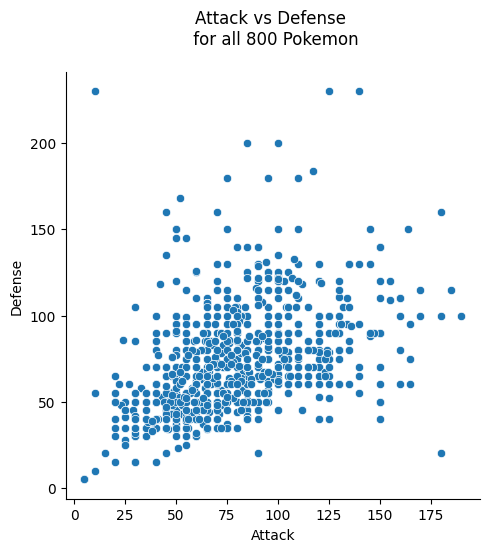

In [4]:
### Relationship plot of Attack vs Defense for every Pokemon
sns.relplot(
    data = pk,
    x = "Attack",
    y = "Defense"
)

## Use plt.title to give the plot a name, pad= to pad the title, and ; to omit the stdout text
plt.title("Attack vs Defense \n for all 800 Pokemon", pad=20);

**From the plot, I observed ....**

There is a **weak-to-moderate positive relationship** between Attack and Defense (Pearson r ≈ 0.44): Pokémon with higher Attack *tend* to have higher Defense, but the trend is loose rather than tight. The points form one large cloud centered roughly between 50–100 Attack and 50–100 Defense, and the cloud fans out as the values grow, so knowing a Pokémon's Attack does **not** let you predict its Defense with any confidence.

The plot also shows that the two stats are traded off at the extremes. A few points sit far up the y-axis with almost no Attack — Shuckle has Defense 230 with Attack 10 — while others sit far to the right with only average Defense, such as Mega Mewtwo X (Attack 190, Defense 100). These "specialist" Pokémon are exactly the ones that break the upward trend.

### Q2: Use hue to add a third variable
Add color via `hue` to the plot above to map the `HP` (hit point) for each datapoint. You can choose your favorite palette. In addition, add a meaningful title. In the markdown cell following the plot, describe if your visualization suggest that the HP status is associated with a particular regions of Attack/Defense space?

*Bonus*: Repeat with Legendary.
Compare the overlap between legendary and non-legendary Pokémon. Does the plot suggest that legendary status is associated with particular regions of Attack/Defense space? Support your answer using the visualization.

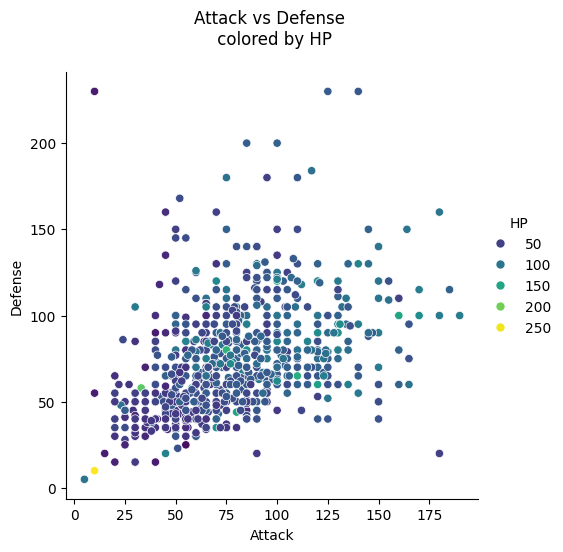

In [5]:
### Add a third variable, HP, using hue. Choose the "viridis" palette
sns.relplot(
    data = pk,
    x = "Attack",
    y = "Defense",
    hue = "HP",
    palette = "viridis"
)

plt.title("Attack vs Defense \n colored by HP", pad=20);

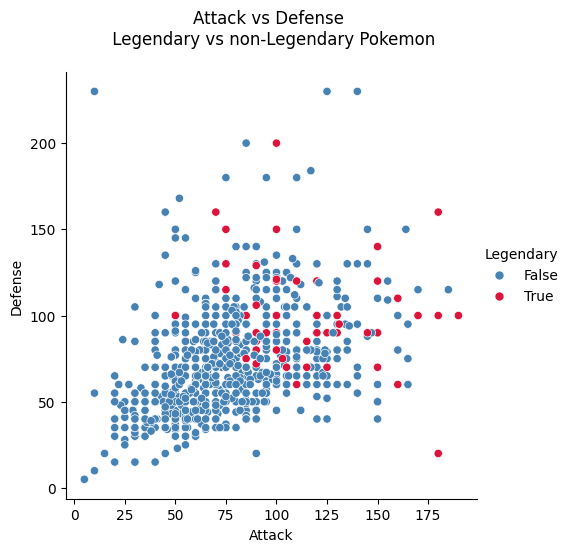

In [6]:
### Bonus: use hue to map Legendary status instead of HP
sns.relplot(
    data = pk,
    x = "Attack",
    y = "Defense",
    hue = "Legendary",
    palette = ["steelblue", "crimson"]
)

plt.title("Attack vs Defense \n Legendary vs non-Legendary Pokemon", pad=20);

**From the plot, I observed ....**

**HP:** the color is only loosely tied to a region of Attack/Defense space. There is a mild tendency for greener (higher-HP) points to sit right of center, which matches the weak positive correlations of HP with Attack (r ≈ 0.42) and with Defense (r ≈ 0.24), but dark low-HP points appear throughout that same region, so no part of the Attack/Defense space is cleanly "high HP". The clearest signal is actually an exception: Blissey (HP 255) and Chansey (HP 250) are the two brightest points and they sit in the **bottom-left corner** with Attack and Defense near 5–10. So HP is best described as mildly associated with the high-Attack/high-Defense region, with dramatic counterexamples.

**Legendary (bonus):** legendary status separates far more cleanly. The red points sit almost entirely in the **upper-right region**, above roughly 80 Attack and 70 Defense — their median Attack is 110 vs 72 for non-legendaries, and median Defense is 100 vs 66. The overlap is still real, though: only 65 of the 800 Pokémon are legendary, and the upper-right region is also populated by blue points (mega evolutions and fully-evolved starters reach the same stats). So high Attack/Defense does **not** imply legendary, but legendary almost always implies high Attack/Defense — the association runs in one direction.

### Q3: Reduce overplotting by changing visualization
Create two `relplot` scatter plots of `Sp. Atk` vs. `Sp. Def`:

1. A standard scatter plot using all Pokémon.
2. A second plot that reduces overplotting by changing transparency (`alpha`) and marker size (`s`).

Use the same axis variables for both plots. Compare the two plots and explain which version makes dense regions easier to see and why.

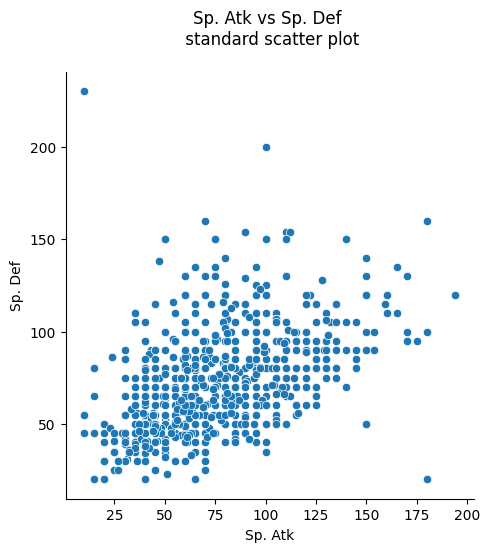

In [7]:
### Plot 1: a standard scatter plot with the default marker size and no transparency
sns.relplot(
    data = pk,
    x = "Sp. Atk",
    y = "Sp. Def"
)

plt.title("Sp. Atk vs Sp. Def \n standard scatter plot", pad=20);

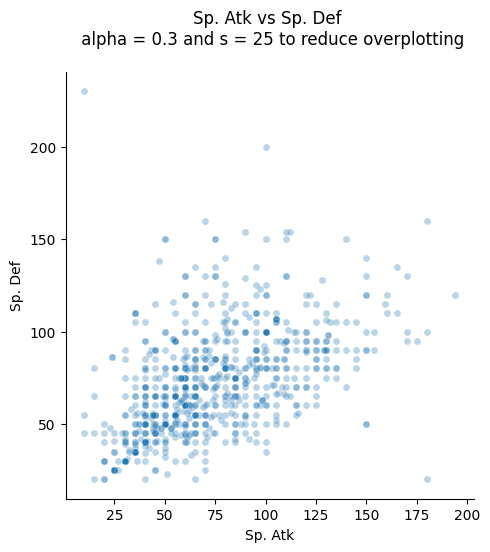

In [8]:
### Plot 2: the same axes, but reduce overplotting with transparency (alpha) and marker size (s)
sns.relplot(
    data = pk,
    x = "Sp. Atk",
    y = "Sp. Def",
    alpha = 0.3,
    s = 25
)

plt.title("Sp. Atk vs Sp. Def \n alpha = 0.3 and s = 25 to reduce overplotting", pad=20);

**From the plot, I observed ....**

The **second plot makes the dense regions much easier to see.** In the first plot the markers are large and fully opaque, so wherever many Pokémon share similar stats the circles simply paint over one another: the middle of the chart becomes one solid blob and every point in it looks identical, whether two Pokémon or fifty are stacked there.

Lowering `alpha` to 0.3 makes each marker semi-transparent, so overlapping markers *add up* — a spot where many Pokémon land renders as a dark patch while an isolated Pokémon renders as a faint dot. Shrinking the marker with `s = 25` reduces how much each point spills over its neighbors. Together they turn "how many points are here" into a visible property of the image, and the darkest area appears around **Sp. Atk 45–65 and Sp. Def 45–70**, which is where the largest number of Pokémon actually sit.

### Q4: Plot the relationship between Attack and Total using a hexbin plot
Create a hexbin plot using seaborn's `jointplot` function. Plot `Attack` on the x-axis and `Total` on the y-axis. You can choose the gridsize. Include a title for the plot. After generating the plot, in the markdown cell following the plot explain what relationship the hexbin plot displays between the  `Attack` and `Total` columns?

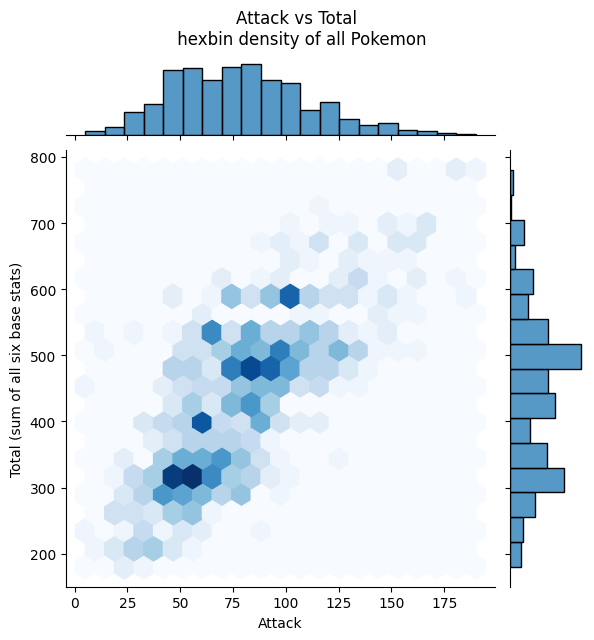

In [9]:
### Hexbin plot of Attack vs Total using jointplot
jp = sns.jointplot(
    data = pk,
    x = "Attack",
    y = "Total",
    kind = "hex",
    gridsize = 20,
    cmap = "Blues"
)

jp.set_axis_labels("Attack", "Total (sum of all six base stats)")

## suptitle is used here because jointplot creates its own figure with marginal plots
jp.figure.suptitle("Attack vs Total \n hexbin density of all Pokemon", y=1.06);

**From the plot, I observed ....**

The hexbin plot shows a clear **positive relationship between Attack and Total** — it is the strongest pairing involving Attack in the whole dataset (r ≈ 0.74). The shaded hexagons run diagonally from the lower left to the upper right: Pokémon with low Attack are concentrated around Totals of 250–350, while Pokémon with Attack above 120 almost all have Totals above 500.

This is partly true *by construction* — `Total` is the sum of the six base stats, and Attack is one of those six — so a large Attack mechanically pulls the Total up. What the hexbins add beyond that is the **density** information a scatter plot hides. The single darkest cell sits near **Attack 50 with Total 310**, and there is a second dark band around **Attack 75–90 with Total 470–500** — these are the two groups the dataset is really made of, unevolved Pokémon and fully-evolved ones. The marginal histograms confirm both variables are right-skewed, with a long thin tail of powerful Pokémon. The spread within each Attack band is also wide: at Attack ≈ 80, Totals run from roughly 300 to 600, because the other five stats can be anything.

### Q5: Investigate density with a second hexbin plot
Create a second `jointplot(kind="hex")`, this time comparing `Sp. Atk` and `Sp. Def`. Choose an appropriate `gridsize`.

Then create the plot again with a noticeably different `gridsize`. Explain how changing `gridsize` changes what you can see about the density of observations. Identify the region containing the greatest concentration of Pokémon.

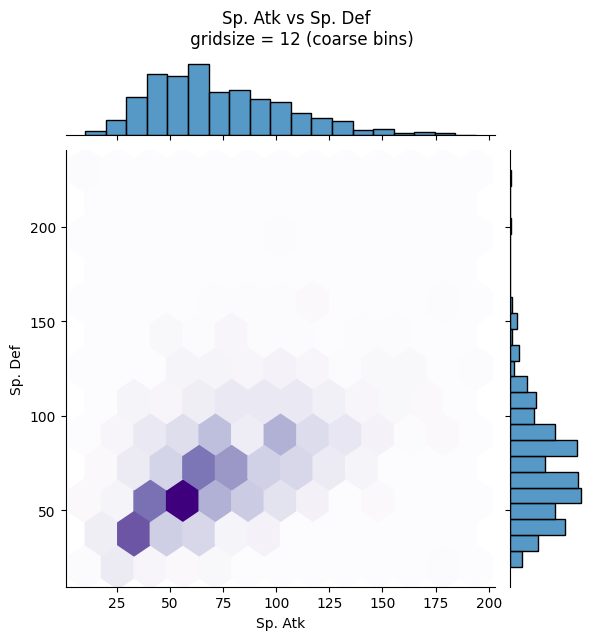

In [10]:
### Hexbin plot of Sp. Atk vs Sp. Def with a small gridsize (large hexagons)
jp_coarse = sns.jointplot(
    data = pk,
    x = "Sp. Atk",
    y = "Sp. Def",
    kind = "hex",
    gridsize = 12,
    cmap = "Purples"
)

jp_coarse.set_axis_labels("Sp. Atk", "Sp. Def")
jp_coarse.figure.suptitle("Sp. Atk vs Sp. Def \n gridsize = 12 (coarse bins)", y=1.06);

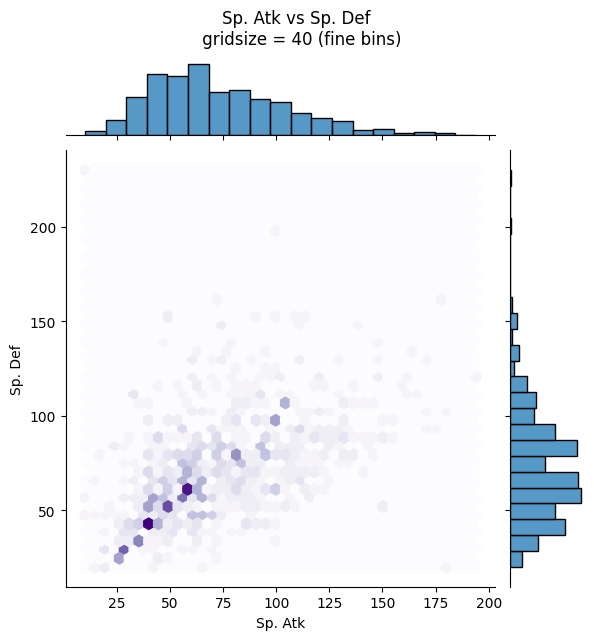

In [11]:
### The same data with a much larger gridsize (small hexagons)
jp_fine = sns.jointplot(
    data = pk,
    x = "Sp. Atk",
    y = "Sp. Def",
    kind = "hex",
    gridsize = 40,
    cmap = "Purples"
)

jp_fine.set_axis_labels("Sp. Atk", "Sp. Def")
jp_fine.figure.suptitle("Sp. Atk vs Sp. Def \n gridsize = 40 (fine bins)", y=1.06);

**From the plot, I observed ....**

`gridsize` controls **how many hexagons the plotting area is divided into**, which is really a choice about how much to smooth the data.

- With `gridsize = 12` the hexagons are large. Each one pools many Pokémon, so the counts per cell are high and the color contrast is strong. The overall *shape* of the distribution is obvious at a glance — a single dense blob in the lower-left with a thin diagonal tail — but the resolution is so coarse that a whole 20-point range of Sp. Atk collapses into one cell, and any fine structure is averaged away.
- With `gridsize = 40` the hexagons are small. Now individual pockets of the data are visible and the boundary of the cloud is sharper, but because the same 800 Pokémon are spread over many more cells, each cell holds only a handful of observations. Most of the plot becomes pale and speckled, and the difference between a cell with 2 Pokémon and one with 4 is hard to read — the plot starts to look like the scatter plot it was meant to replace.

Both versions agree on where the data piles up. The **greatest concentration of Pokémon is around Sp. Atk 50–65 and Sp. Def 50–65**, at or just below the median of each stat (median Sp. Atk = 65, median Sp. Def = 70). In the coarse version the single darkest hexagon is centered near Sp. Atk ≈ 55, Sp. Def ≈ 55, and the fine version splits that same peak into two adjacent dark cells near (40, 45) and (58, 62) — the location of the peak agrees, only its resolution changes. The relationship between the two stats is positive but only moderate (r ≈ 0.51), which is why the cloud is a fat diagonal smear rather than a tight line.

### Q6: Create two categorical plots for Pokemon types. `Type 1` and `Type 2` .
For each plot, the unique values of `Type 1` or `Type 2` should be plotted along the y-axis, and the counts of Pokemon should be on the x-axis. Use the color red for the `Type 1` plot and blue for the `Type 2` plot. After the two plots are displayed, insert a markdown cell to write your findings: Which are the most common `Type 1` and `Type 2` Pokemons, and which are the most rare ones?

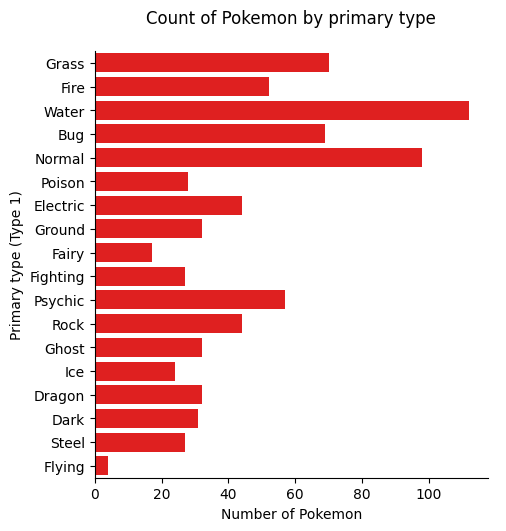

In [12]:
### Count plot of the primary type (Type 1) in red, with the types along the y-axis
t1 = sns.catplot(
    data = pk,
    y = "Type 1",
    kind = "count",
    color = "red"
)

t1.set_axis_labels("Number of Pokemon", "Primary type (Type 1)")
plt.title("Count of Pokemon by primary type", pad=20);

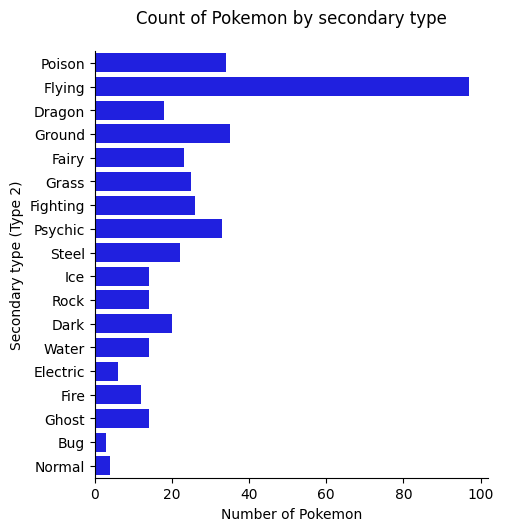

In [13]:
### Count plot of the secondary type (Type 2) in blue
### Note: catplot ignores the 386 Pokemon whose Type 2 is missing (NaN)
t2 = sns.catplot(
    data = pk,
    y = "Type 2",
    kind = "count",
    color = "blue"
)

t2.set_axis_labels("Number of Pokemon", "Secondary type (Type 2)")
plt.title("Count of Pokemon by secondary type", pad=20);

**From the plot, I observed ....**

**Type 1 (primary).** The most common primary types are **Water (112)**, **Normal (98)**, and **Grass (70)**, followed closely by Bug (69). The rarest by a wide margin is **Flying, with only 4** Pokémon; **Fairy (17)** and **Ice (24)** are next-rarest. The distribution is heavily unbalanced — Water alone accounts for 14% of all 800 Pokémon, about 28 times as many as Flying.

**Type 2 (secondary).** Only 414 of the 800 Pokémon have a secondary type at all; the other 386 are single-type and are dropped from this plot. Among those that do, **Flying (97)** dominates, more than twice the next most common, **Ground (35)** and **Poison (34)**. The rarest secondary types are **Bug (3)**, **Normal (4)**, and **Electric (6)**.

**The interesting finding is Flying.** It is the *rarest* primary type (4) and the *most common* secondary type (97). Flying is almost never a Pokémon's defining identity — it is an attribute bolted onto a bird, bug, or dragon that already has another type. The two plots only reveal this because they are read together; either one alone would give the opposite impression of how common Flying is.

### Q7: Order a categorical count plot
Create a `catplot(kind="count")` for `Type 1`. Plot Pokémon types on the **y-axis** and counts on the **x-axis**. Order the categories from most common to least common using `value_counts().index`, and add meaningful axis labels.

After plotting, explain how ordering the categories can make the graph easier to interpret compared to an unordered count plot.


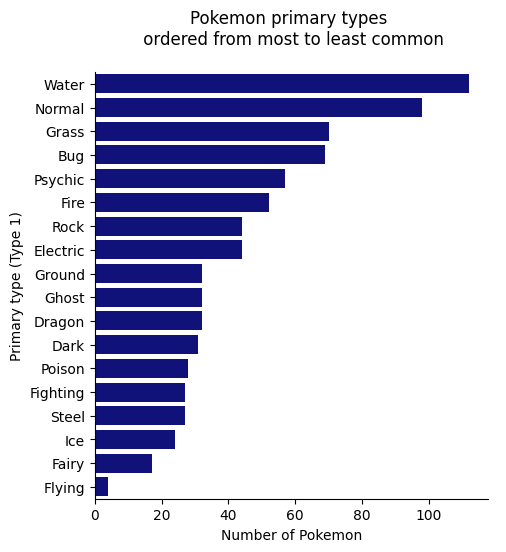

In [14]:
### Improving the count plot by ordering the bars from most common to least common
### value_counts() is already sorted, so .index gives the type names in descending order
ordered = sns.catplot(
    data = pk,
    y = "Type 1",
    kind = "count",
    order = pk["Type 1"].value_counts().index,
    color = "darkblue"
)

ordered.set_axis_labels("Number of Pokemon", "Primary type (Type 1)")
plt.title("Pokemon primary types \n ordered from most to least common", pad=20);

**From the plot, I observed ....**

Ordering turns the chart into a **ranking** instead of a lookup table. In the unordered plot of Q6 the bars appear in the order the types happen to show up in the data, so answering "which type is third most common?" means scanning every bar and mentally sorting them. Here the answer is read straight off the top of the chart: Water, Normal, Grass, Bug, Psychic, Fire.

Ordering also makes **comparisons between neighbors reliable**. Bars of similar length are now placed next to each other, so close calls like Grass (70) vs. Bug (69) are easy to judge; when those bars are separated by half the chart the eye cannot compare them accurately. The monotonic staircase shape additionally makes the *shape* of the distribution visible at a glance — a few very common types followed by a long, slowly declining tail, ending at Flying with just 4 — which is information the unordered version scrambles completely.

Putting the types on the y-axis matters too: the type names print horizontally and stay readable, instead of being crammed or rotated along the x-axis.

### Q8: Compare Attack distributions among common Pokémon types
Identify the five most common `Type 1` categories. Filter the dataframe to those five types, then create a Seaborn `catplot(kind="box")` with `Type 1` and `Attack`.

Use the plot to compare the center and spread of Attack values. Which types appear to have higher median Attack? Which show the greatest variability?


In [15]:
### Find the five most common primary types
top5 = pk["Type 1"].value_counts().nlargest(5).index
print("Five most common Type 1 categories:", list(top5))

### Filter the DataFrame down to just those five types
pk_top5 = pk[pk["Type 1"].isin(top5)]
print("Number of Pokemon in the filtered DataFrame:", len(pk_top5))

Five most common Type 1 categories: ['Water', 'Normal', 'Grass', 'Bug', 'Psychic']
Number of Pokemon in the filtered DataFrame: 406


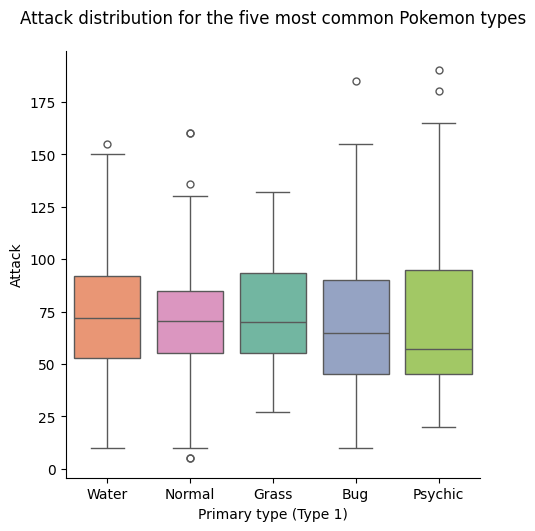

In [16]:
### Box plot comparing the Attack distribution of the five most common types
box = sns.catplot(
    data = pk_top5,
    x = "Type 1",
    y = "Attack",
    kind = "box",
    order = top5,
    palette = "Set2",
    hue = "Type 1",
    legend = False
)

box.set_axis_labels("Primary type (Type 1)", "Attack")
plt.title("Attack distribution for the five most common Pokemon types", pad=20);

**From the plot, I observed ....**

**Center.** The five medians are remarkably close together — **Water 72, Normal 70.5, Grass 70, Bug 65, Psychic 57**. Water has the highest median Attack and Psychic the lowest, but the gap between the top four is only about 7 points, which is small next to the spread *within* each type. The main conclusion is that primary type is a weak predictor of Attack: a random Water Pokémon is only slightly more likely to hit hard than a random Grass one.

**Spread.** The types differ far more in variability than in center. **Psychic is the most variable** — its box is the tallest (45 to 95, IQR = 50), its standard deviation of 42.3 is the largest of the five, and it carries outliers at 180 and 190 (Mega Mewtwo X), so it holds both the weakest and the strongest attackers. **Bug is second** (IQR 45–90, with an outlier at 185 for Mega Heracross) and its lower whisker reaches down to 10.

**Grass is the most consistent.** Its standard deviation is the smallest (25.4), its maximum is the lowest (132), and it is the only one of the five with **no outliers at all** — every Grass Pokémon falls inside its whiskers. Normal has the narrowest box (55–85) but that box is misleading on its own: its whiskers and outliers stretch from 5 all the way to 160, which is why the box plot is worth reading as a whole rather than by its median alone.

### Q9 and Q10: Your own questions
Come up with two additional questions that can be answered visually using the Pokémon dataset. Your questions should use Seaborn and should not simply repeat Q1–Q8. For each question:

* State the data question clearly
* Choose an appropriate Seaborn visualization. Use different visualization strategies across your two questions.
* Include a meaningful title and informative axes labels
* Write 2–3 sentences interpreting the visualization

### Q9: Which of the six base stats varies the most across all Pokémon?

**The data question:** `Total` is the sum of six base stats (HP, Attack, Defense, Sp. Atk, Sp. Def, Speed). Are those six stats distributed the same way, or do some of them spread much more widely than others?

**The visualization:** a **violin plot**. The six stats live in six separate columns, so the DataFrame is first reshaped from wide to long form with `pandas.melt()`, which is what Seaborn's categorical functions expect. A violin plot is used rather than the box plot of Q8 because it draws the full KDE of each distribution, so multi-peaked or lopsided shapes are visible, not just the quartiles.

In [17]:
### Reshape the six base stat columns from wide form into long (tidy) form using melt()
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]

pk_long = pk.melt(
    id_vars = ["Name", "Legendary"],
    value_vars = stats,
    var_name = "Stat",
    value_name = "Value"
)

pk_long.head()

,Name,Legendary,Stat,Value
0,Bulbasaur,False,HP,45
1,Ivysaur,False,HP,60
2,Venusaur,False,HP,80
3,VenusaurMega Venusaur,False,HP,80
4,Charmander,False,HP,39


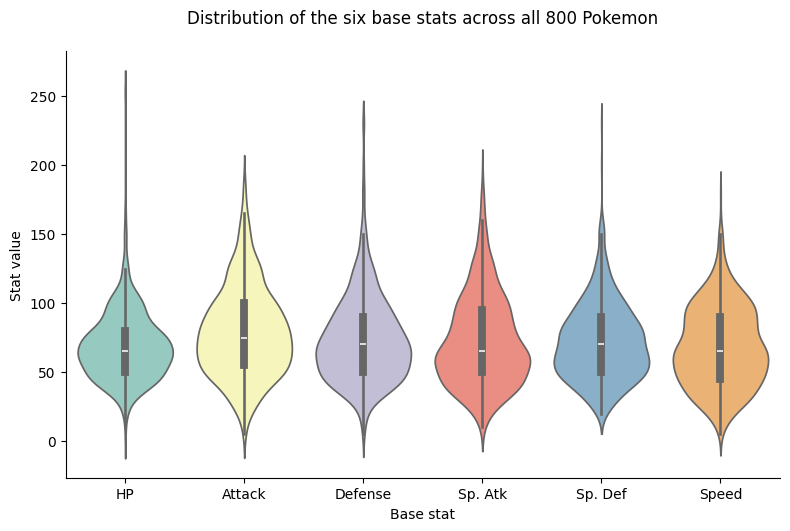

In [18]:
### Violin plot showing the full distribution of each of the six base stats
vp = sns.catplot(
    data = pk_long,
    x = "Stat",
    y = "Value",
    kind = "violin",
    order = stats,
    palette = "Set3",
    hue = "Stat",
    legend = False,
    height = 5,
    aspect = 1.6
)

vp.set_axis_labels("Base stat", "Stat value")
plt.title("Distribution of the six base stats across all 800 Pokemon", pad=20);

**From the plot, I observed ....**

The six stats are **not** distributed alike. **Sp. Atk (sd 32.7) and Attack (sd 32.5) are the widest**, with fat violins that stay thick well past 100 — these are the stats a designer is willing to push to extremes. **HP is the narrowest through its middle (sd 25.5)** but has by far the longest, thinnest tail, stretching all the way to 255 for Blissey; the violin is a narrow spike at the top because only a handful of Pokémon live up there.

All six violins are **unimodal and right-skewed**, each peaking in a narrow band between 57 and 67 and then trailing upward into a thin tail — no stat has a second bulge of "strong" Pokémon, which means power is a matter of degree rather than two separate classes. What the violin adds over a box plot is the *shape* of the body: Attack's violin is visibly the fattest through 55–105 (IQR = 45), meaning attackers really are spread across that whole range, while HP's is pinched tightly around 65 (IQR = 30) despite having the most extreme outlier of all. Defense and Sp. Def show the same pattern as HP in miniature, with needle-thin spikes up to 230 for the handful of walls like Shuckle, Steelix and Aggron.

### Q10: Which base stats move together, and which are independent?

**The data question:** Q1 showed Attack and Defense are only loosely related. Rather than checking each of the 15 possible pairs with its own scatter plot, which pairs of stats are most and least correlated overall?

**The visualization:** a **heatmap** of the correlation matrix. This is a completely different strategy from the scatter, hexbin, count and box/violin plots used above — it summarises all 15 pairwise relationships in one grid, using color rather than position to encode the value. A diverging palette centered on zero is used so positive and negative correlations are distinguishable at a glance.

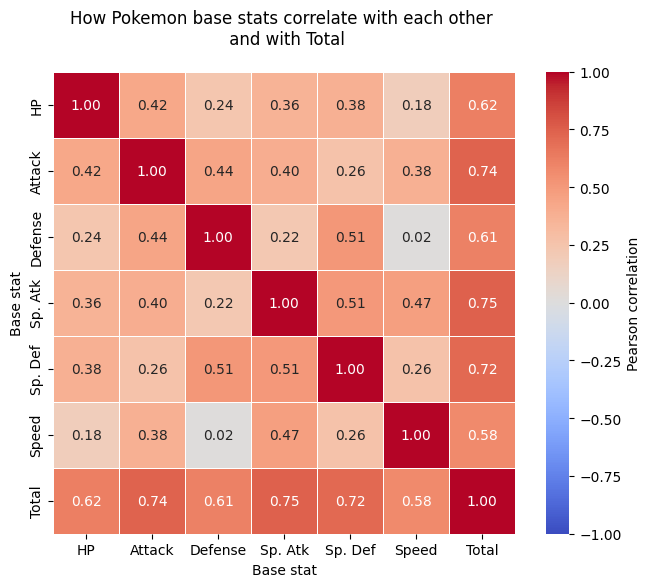

In [19]:
### Compute the correlation matrix for the six base stats plus Total
corr = pk[stats + ["Total"]].corr()

### Draw it as a heatmap. annot=True prints the value in each cell,
### and vmin/vmax/center fix the diverging color scale around 0
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0,
    square = True,
    linewidths = 0.5,
    cbar_kws = {"label": "Pearson correlation"}
)

plt.title("How Pokemon base stats correlate with each other \n and with Total", pad=20)
plt.xlabel("Base stat")
plt.ylabel("Base stat");

**From the plot, I observed ....**

Every correlation in the grid is **positive** — there are no blue cells — so no two stats genuinely trade off against each other across the dataset as a whole. The `Total` row is the warmest, which is expected since Total is the sum of the other six; within that row, **Sp. Atk (0.75) and Attack (0.74) contribute most** to a Pokémon's overall power, while **Speed (0.58) contributes least**.

Among the base stats themselves, the strongest pairs are **Defense–Sp. Def (0.51)** and **Sp. Atk–Sp. Def (0.51)**: defensive stats travel together, and so do the two "special" stats. The weakest relationship in the entire matrix is **Defense–Speed (0.02)**, which is effectively zero — knowing how bulky a Pokémon is tells you nothing whatsoever about how fast it is. That single cell captures the classic speed/bulk design split more compactly than a scatter plot would, and it is the kind of near-zero result that is easy to miss unless every pair is examined at once.

##Bonus Questions

### B1: Map both hue and point size
Create a `relplot` with `Attack` on the x-axis and `Defense` on the y-axis. Map `Speed` to `hue` and `Total` to `size`. Choose a reasonable `sizes=(min, max)` range so that the points remain readable.

Describe what information is represented by position, color, and point size. What pattern, if any, do you notice among Pokémon with high `Total` values?


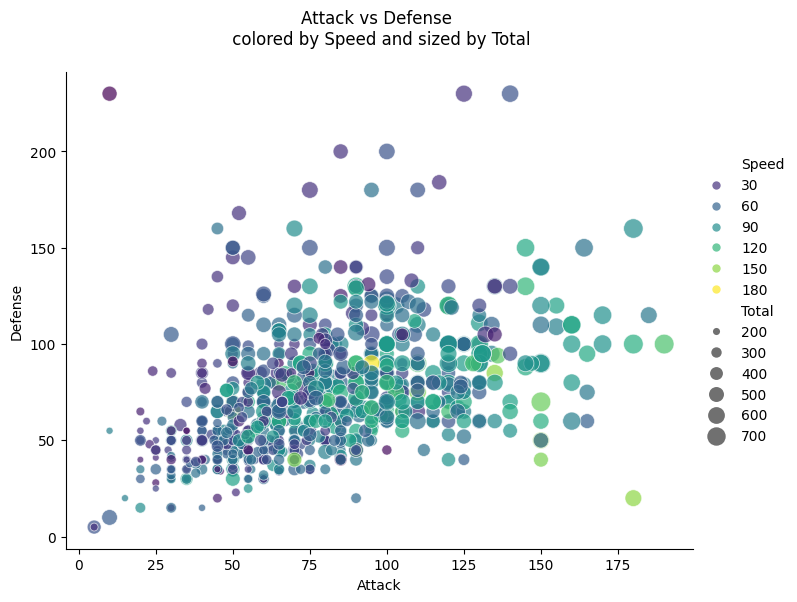

In [20]:
### Map four variables at once: position (Attack, Defense), color (Speed) and size (Total)
sns.relplot(
    data = pk,
    x = "Attack",
    y = "Defense",
    hue = "Speed",
    palette = "viridis",
    size = "Total",
    sizes = (20, 200),
    alpha = 0.7,
    height = 5.5,
    aspect = 1.3
)

plt.title("Attack vs Defense \n colored by Speed and sized by Total", pad=20);

**From the plot, I observed ....**

**What each channel encodes.** *Position* carries the two stats being compared — Attack on the x-axis, Defense on the y-axis. *Color* carries Speed on a continuous viridis scale, with dark purple for slow Pokémon and bright yellow-green for fast ones. *Size* carries Total, so the marker area grows with a Pokémon's overall power, scaled between 20 and 200 points so the smallest markers stay visible and the largest do not swallow their neighbors.

**The pattern among high-Total Pokémon.** The large markers are not scattered at random — they cluster toward the **upper right**, which is the direct visual consequence of Attack and Defense each being components of Total. More interestingly, those large markers also skew **bright**: among the 85 Pokémon with Total ≥ 600 the median Speed is 99, against 65 for the dataset as a whole, and 54% of them are legendary. So the strongest Pokémon tend to be strong in *every* dimension at once rather than specializing.

**The exceptions are what make the plot worth reading.** A few large markers sit high on the Defense axis but are very dark — Mega Steelix and Mega Aggron, with Defense 230 and Speed around 30. These are Pokémon that spent their entire stat budget on bulk, and only the combination of size and color reveals them; with `hue` alone they would look like ordinary slow Pokémon, and with `size` alone like ordinary strong ones.

### B2: Subsample the dataset
Use pandas `.sample()` to randomly select **200 Pokémon**, then create a `relplot` of `Attack` vs. `Defense` from the sample. Use a random seed by setting `random_state=1` so that your result is reproducible. Compare this plot with your Q1 plot that used the full dataset.

What information can be lost when subsampling? What is one reason subsampling can still be useful when working with very large datasets?


Rows in the sample: 200


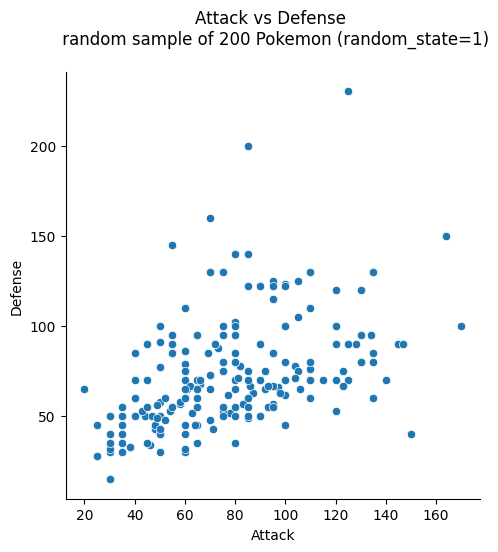

In [21]:
### Randomly select 200 Pokemon. random_state=1 makes the sample reproducible
pk_sample = pk.sample(200, random_state=1)
print("Rows in the sample:", len(pk_sample))

sns.relplot(
    data = pk_sample,
    x = "Attack",
    y = "Defense"
)

plt.title("Attack vs Defense \n random sample of 200 Pokemon (random_state=1)", pad=20);

**From the plot, I observed ....**

**What survives.** The overall structure is reproduced faithfully. The sample still shows one loose cloud centered near 50–100 on both axes, and the correlation between Attack and Defense is essentially unchanged (r ≈ 0.47 in the sample vs. 0.44 in the full dataset). For judging the *shape and strength* of the main relationship, a quarter of the data was enough.

**What is lost.** The rare extremes thin out, and rare cases are exactly what the tails of a scatter plot are made of. Only **2 of the 5** Pokémon with Defense ≥ 200 made it into the sample, and the maximum Attack drops from **190 (Mega Mewtwo X) to 170** — the single most extreme attacker in the game simply is not there. Density is also distorted: with 200 instead of 800 points the crowded middle looks far less crowded, which would lead to underestimating how typical the mid-range really is. Anything rare — legendaries, mega evolutions, one-off outliers — is at risk of vanishing, and a plot cannot show what is not in it.

**Why subsample anyway.** With hundreds of thousands of rows a scatter plot becomes a solid unreadable mass (the overplotting problem of Q3, but unfixable by `alpha` alone) and both rendering and the exploratory loop slow to a crawl. Plotting a sample keeps the figure legible and the iteration fast while preserving the broad pattern, which is usually what an exploratory plot is for. The usual practice is to explore on a sample and then confirm anything that matters — especially anything about outliers — on the full dataset.

### B3: Compare groups with a multi-panel relationship plot
Use `sns.relplot()` to compare `Attack` vs. `Defense` across Pokémon generations. Set `col="Generation"` so that each generation is displayed in a separate panel. Use `hue="Legendary"` to distinguish legendary from non-legendary Pokémon.

After plotting, identify one similarity and one difference you observe across generations. How can the implementation of multi-panel plot make it easier to interpret compare to  placing every group on one set of axes?


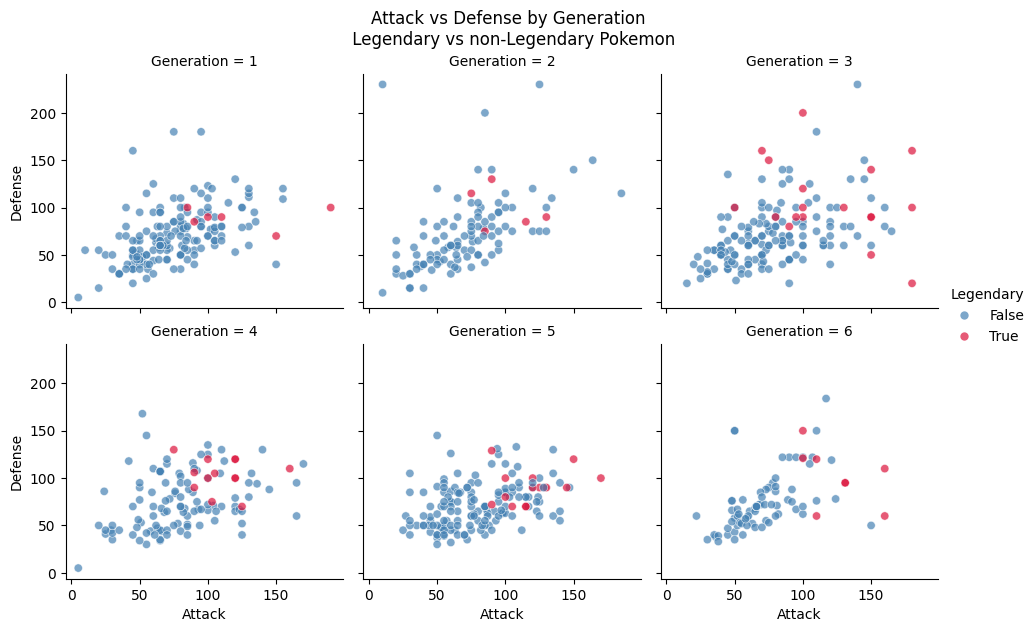

In [22]:
### Multi-panel (faceted) plot: one panel per Generation, colored by Legendary status
### col_wrap=3 arranges the six panels into two rows of three
g = sns.relplot(
    data = pk,
    x = "Attack",
    y = "Defense",
    col = "Generation",
    col_wrap = 3,
    hue = "Legendary",
    palette = ["steelblue", "crimson"],
    alpha = 0.7,
    height = 3.2
)

g.set_axis_labels("Attack", "Defense")

## Make room for a figure-level title above the grid of panels
g.figure.subplots_adjust(top=0.88)
g.figure.suptitle("Attack vs Defense by Generation \n Legendary vs non-Legendary Pokemon");

**From the plot, I observed ....**

**One similarity.** Every generation produces the same basic picture: a loose, positively-sloped cloud of blue points centered around 50–100 Attack and 50–100 Defense, with the red legendary points pushed into the upper-right corner. Six separate games designed over roughly two decades kept the stat distribution essentially stable — nothing in these panels suggests a redesign of how ordinary Pokémon are statted.

**One difference.** The number of legendaries per generation varies sharply. Generations 1 and 2 have almost none — **6 and 5** red points respectively — while **Generation 3 has 18**, the most of any panel, and Generations 4 and 5 have 13 and 15. Generation 4 also has the highest median Total (485, vs. about 435 for Generations 1 and 3), and its cloud does sit slightly further from the origin — median Attack 80 and Defense 72, against 75 and 66 in Generation 1. Legendaries became a much larger part of each release after Generation 2.

**Why faceting helps.** Putting all six generations on one set of axes would mean 800 points in a single frame distinguished only by color, so the generations would overlap almost completely and the eye could not isolate one group from another. Splitting them into panels makes each generation's cloud independently readable while `relplot` keeps the **x and y axes shared across all panels**, so the panels remain directly comparable — a point in the same screen position means the same stats in every panel. This frees `hue` to carry a second variable, Legendary, and a two-variable comparison (generation × legendary status) becomes readable in one figure. The cost is that comparing two generations now requires moving the eye between panels rather than reading one overlaid plot, which is why faceting suits *many* groups and overlay suits *two or three*.